# TecnoForms - Reconocimiento de dígitos manuscritos
Trabajo final de Machine Learning y Deep Learning

Modelos: CNN (red neuronal), KNN y SVM. Dataset: MNIST (datos de internet).

## 1. Librerías

In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import tensorflow as tf
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import cv2

## 2. Carga del dataset

In [99]:
mnist= fetch_openml('mnist_784', version=1, as_frame= False) #las imágenes ya están aplanadas (784 = 28x28)
x= mnist.data.astype('float32')
y= mnist.target.astype('int32')
print(x.shape)
print(y.shape)
print(x[0].shape)
print('Clases', np.unique(y))

(70000, 784)
(70000,)
(784,)
Clases [0 1 2 3 4 5 6 7 8 9]


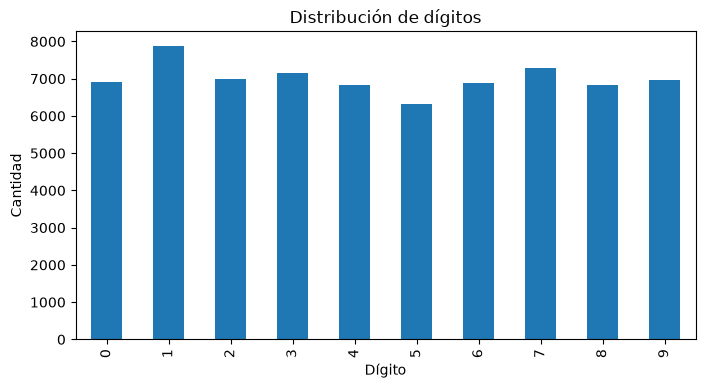

In [100]:
#cantidad de muestras por dígito
pd.Series(y).value_counts().sort_index().plot(kind='bar', figsize=(8,4))
plt.title('Distribución de dígitos')
plt.xlabel('Dígito')
plt.ylabel('Cantidad')
plt.show()

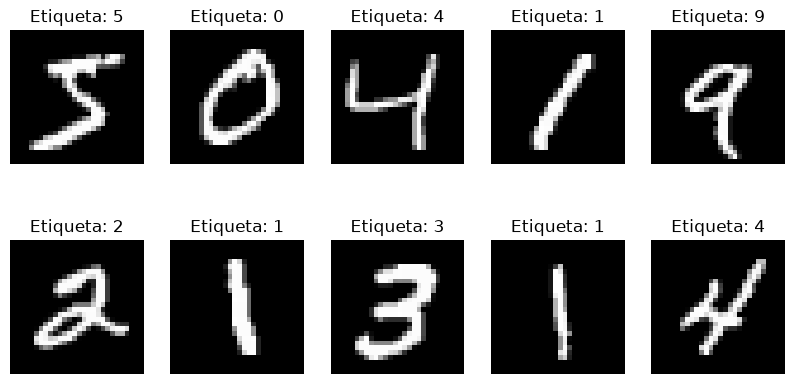

In [101]:
#muestras del dataset
plt.figure(figsize=(10,5))
for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(x[i].reshape(28,28), cmap='gray')
  plt.title('Etiqueta: '+str(y[i]))
  plt.axis('off')
plt.show()

## 3. Preprocesamiento
Normalización de los píxeles (0-255 a 0-1). Las imágenes de MNIST ya están en escala de grises y centradas.

(Pendiente: conversión a escala de grises, normalización y segmentación sobre imágenes de formularios.)

In [102]:
x= x/255 #NORMALIZAMOS LAS IMÁGENES
print('Mínimo', x.min(), 'Máximo', x.max())

Mínimo 0.0 Máximo 1.0


In [103]:
x_train, x_test, y_train, y_test= train_test_split(x,y,test_size=0.2, random_state=42)
print(x_train.shape, x_test.shape)

(56000, 784) (14000, 784)


## 4. Funciones de evaluación

In [104]:
resultados= {} #aquí guardamos las métricas de cada modelo para compararlos al final
predicciones= {}

def evaluar(nombre, y_real, y_pred, tiempo=None):
  acc= accuracy_score(y_real, y_pred)
  prec= precision_score(y_real, y_pred, average='macro', zero_division=0)
  rec= recall_score(y_real, y_pred, average='macro', zero_division=0)
  f1= f1_score(y_real, y_pred, average='macro', zero_division=0)
  resultados[nombre]= {'Accuracy':acc, 'Precision':prec, 'Recall':rec, 'F1':f1, 'Tiempo (s)':tiempo}
  predicciones[nombre]= y_pred
  print('Metricas del modelo', nombre)
  print('Accuracy', acc)
  print(classification_report(y_real, y_pred, zero_division=0))

def matriz_confusion(nombre, y_real, y_pred):
  cm= confusion_matrix(y_real, y_pred)
  plt.figure(figsize=(8,6))
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
  plt.title('Matriz de confusión - '+nombre)
  plt.xlabel('Predicción')
  plt.ylabel('Etiqueta real')
  plt.show()

## 5. Modelo 1: CNN (red neuronal convolucional)

In [105]:
#RNA CONVOLUCIONAL
x_train_cnn= x_train.reshape(-1,28,28,1) #las imágenes ya NO están aplanadas
x_test_cnn= x_test.reshape(-1,28,28,1)

model_cnn= tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),
    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(), #reducimos la dimensionalidad del mapa de características
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(), #aplanamos para procesar en capas densas
    #LA PREDICCIÓN FINAL LA TOMAN LAS CAPAS DENSAS
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax'),
])
model_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_cnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 3, 3, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 1, 1, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,106 (109.79 KB)

 Trainable params: 28,106 (109.79 KB)

 Non-trainable params: 0 (0.00 B)

In [106]:
t0= time.time()
historial= model_cnn.fit(x_train_cnn, y_train, epochs=10, validation_split=0.1)
t_cnn= time.time()-t0

Epoch 1/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9149 - loss: 0.2712 - val_accuracy: 0.9679 - val_loss: 0.0957
Epoch 2/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9737 - loss: 0.0869 - val_accuracy: 0.9784 - val_loss: 0.0695
Epoch 3/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9804 - loss: 0.0642 - val_accuracy: 0.9821 - val_loss: 0.0577
Epoch 4/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9838 - loss: 0.0521 - val_accuracy: 0.9818 - val_loss: 0.0556
Epoch 5/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9870 - loss: 0.0434 - val_accuracy: 0.9845 - val_loss: 0.0491
Epoch 6/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9885 - loss: 0.0376 - val_accuracy: 0.9845 - val_loss: 0.0514
Epoch 7/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9896 - loss: 0.0316 - val_accuracy: 0.9861 - val_loss: 0.0560
Epoch 8/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9913 - loss: 0.0266 - 

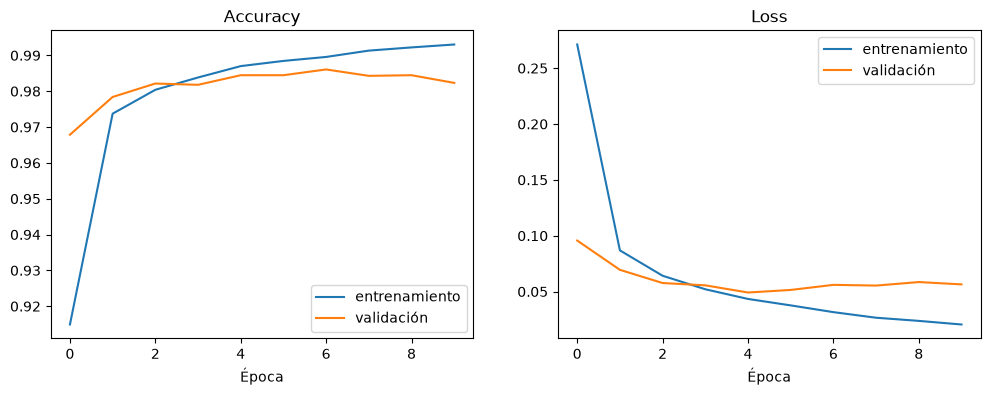

In [107]:
#curvas de entrenamiento
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(historial.history['accuracy'], label='entrenamiento')
plt.plot(historial.history['val_accuracy'], label='validación')
plt.title('Accuracy')
plt.xlabel('Época')
plt.legend()
plt.subplot(1,2,2)
plt.plot(historial.history['loss'], label='entrenamiento')
plt.plot(historial.history['val_loss'], label='validación')
plt.title('Loss')
plt.xlabel('Época')
plt.legend()
plt.show()

438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Metricas del modelo CNN
Accuracy 0.9815
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1343
           1       0.99      1.00      0.99      1600
           2       0.97      0.99      0.98      1380
           3       0.99      0.98      0.99      1433
           4       0.99      0.94      0.97      1295
           5       0.99      0.97      0.98      1273
           6       0.99      0.99      0.99      1396
           7       0.98      0.98      0.98      1503
           8       0.98      0.98      0.98      1357
           9       0.94      0.99      0.96      1420

    accuracy                           0.98     14000
   macro avg       0.98      0.98      0.98     14000
weighted avg       0.98      0.98      0.98     14000



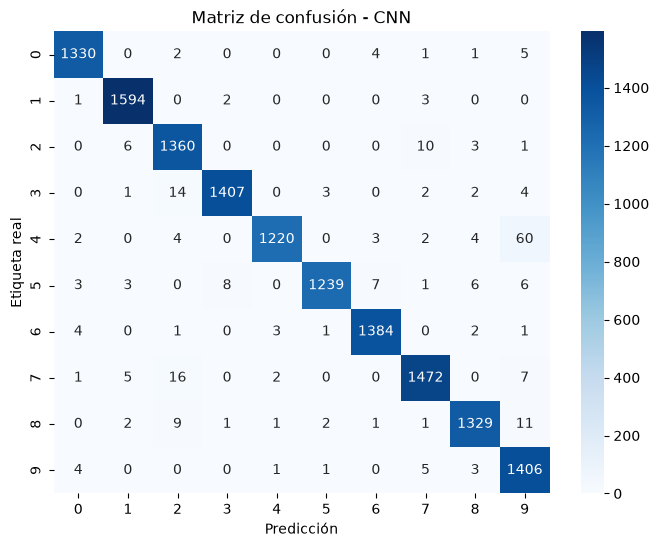

In [108]:
y_pred_cnn= model_cnn.predict(x_test_cnn).argmax(1)
evaluar('CNN', y_test, y_pred_cnn, t_cnn)
matriz_confusion('CNN', y_test, y_pred_cnn)

## 6. Modelo 2: KNN

Metricas del modelo KNN
Accuracy 0.9700714285714286
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1343
           1       0.96      0.99      0.98      1600
           2       0.98      0.96      0.97      1380
           3       0.97      0.97      0.97      1433
           4       0.97      0.97      0.97      1295
           5       0.97      0.97      0.97      1273
           6       0.98      0.99      0.98      1396
           7       0.96      0.97      0.97      1503
           8       0.99      0.93      0.96      1357
           9       0.95      0.96      0.96      1420

    accuracy                           0.97     14000
   macro avg       0.97      0.97      0.97     14000
weighted avg       0.97      0.97      0.97     14000



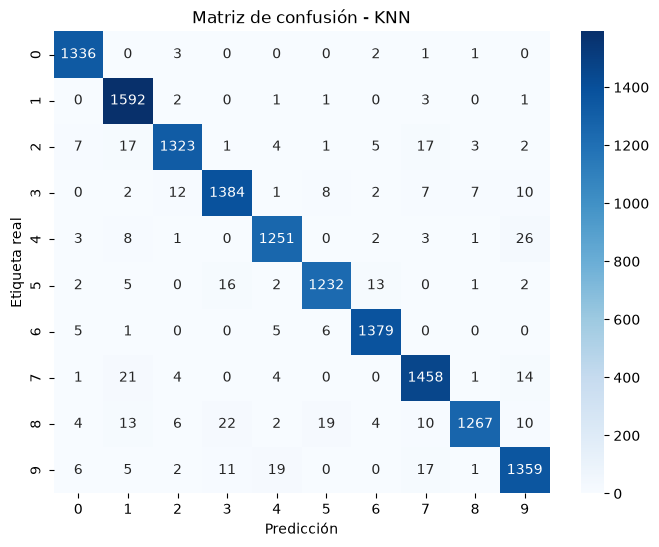

In [109]:
t0= time.time()
model_knn= KNeighborsClassifier()
model_knn.fit(x_train, y_train)
y_pred_knn= model_knn.predict(x_test)
t_knn= time.time()-t0
evaluar('KNN', y_test, y_pred_knn, t_knn)
matriz_confusion('KNN', y_test, y_pred_knn)

## 7. Modelo 3: SVM
SVC con kernel rbf es lento con 56000 muestras, por eso se entrena con un subconjunto (N_SVM) y se evalúa con todo el test. Se puede subir N_SVM si la computadora lo permite.

Metricas del modelo SVM
Accuracy 0.9675
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1343
           1       0.98      0.99      0.98      1600
           2       0.96      0.96      0.96      1380
           3       0.95      0.95      0.95      1433
           4       0.96      0.97      0.97      1295
           5       0.96      0.96      0.96      1273
           6       0.98      0.98      0.98      1396
           7       0.97      0.97      0.97      1503
           8       0.97      0.94      0.96      1357
           9       0.96      0.96      0.96      1420

    accuracy                           0.97     14000
   macro avg       0.97      0.97      0.97     14000
weighted avg       0.97      0.97      0.97     14000



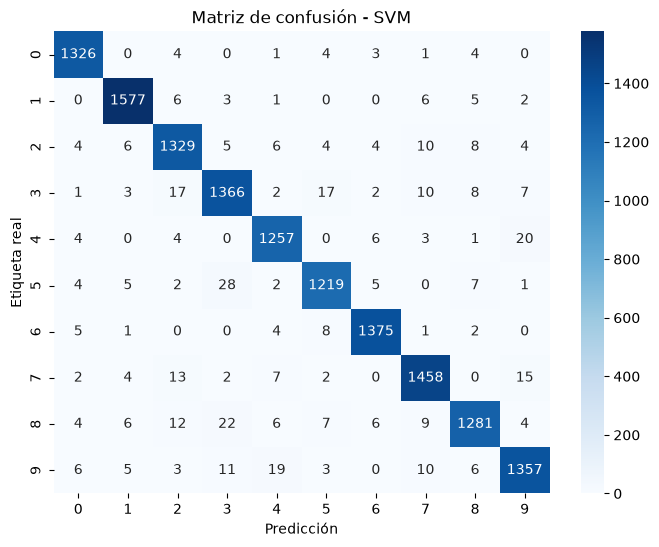

In [110]:
N_SVM= 10000
t0= time.time()
model_svm= SVC(kernel='rbf', C=5, gamma='scale')
model_svm.fit(x_train[:N_SVM], y_train[:N_SVM])
y_pred_svm= model_svm.predict(x_test)
t_svm= time.time()-t0
evaluar('SVM', y_test, y_pred_svm, t_svm)
matriz_confusion('SVM', y_test, y_pred_svm)

## 8. Comparación de modelos

In [111]:
tabla= pd.DataFrame(resultados).T
tabla= tabla.sort_values('Accuracy', ascending=False)
tabla

,Accuracy,Precision,Recall,F1,Tiempo (s)
CNN,0.981500,0.982023,0.980960,0.981322,58.279683
KNN,0.970071,0.970655,0.969671,0.970028,5.625640
SVM,0.967500,0.967321,0.967214,0.967243,28.242719


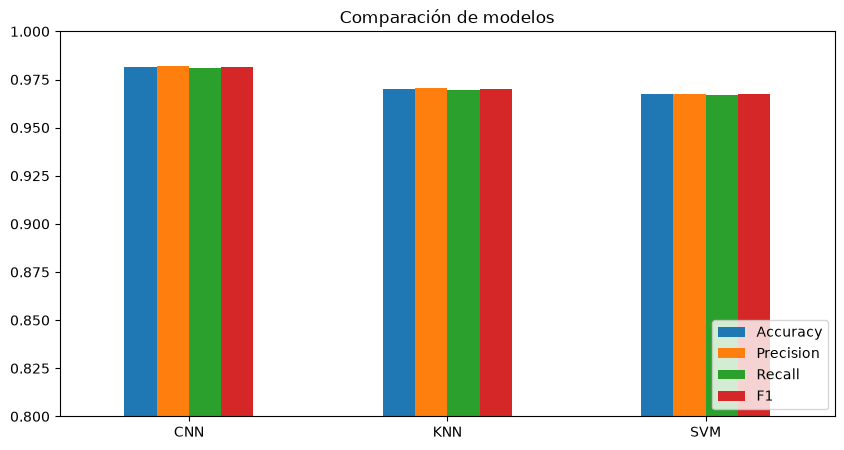

In [112]:
tabla[['Accuracy','Precision','Recall','F1']].plot(kind='bar', figsize=(10,5))
plt.title('Comparación de modelos')
plt.ylim(0.8,1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

## 9. Resultados visuales: predicciones vs etiquetas reales (CNN)

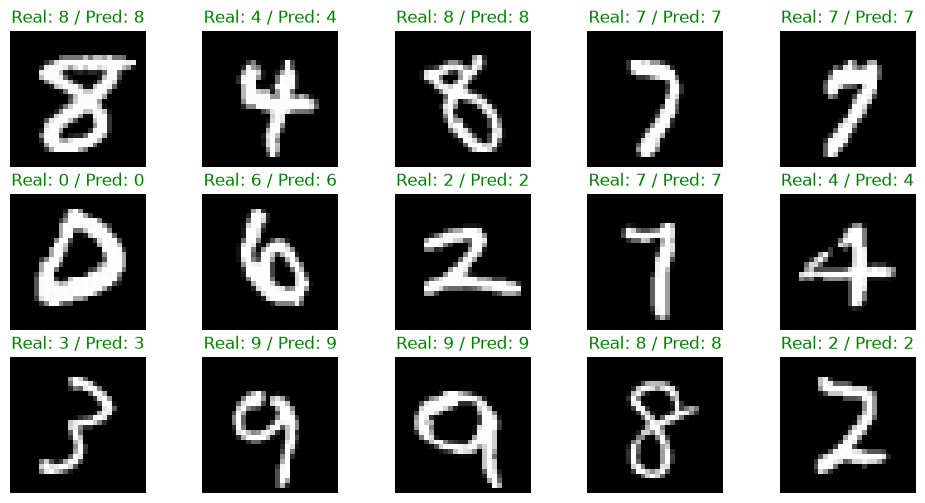

In [113]:
plt.figure(figsize=(12,6))
for i in range(15):
  plt.subplot(3,5,i+1)
  plt.imshow(x_test[i].reshape(28,28), cmap='gray')
  real= y_test[i]
  pred= y_pred_cnn[i]
  plt.title('Real: '+str(real)+' / Pred: '+str(pred), color='green' if real==pred else 'red')
  plt.axis('off')
plt.show()

Cantidad de errores 259 de 14000


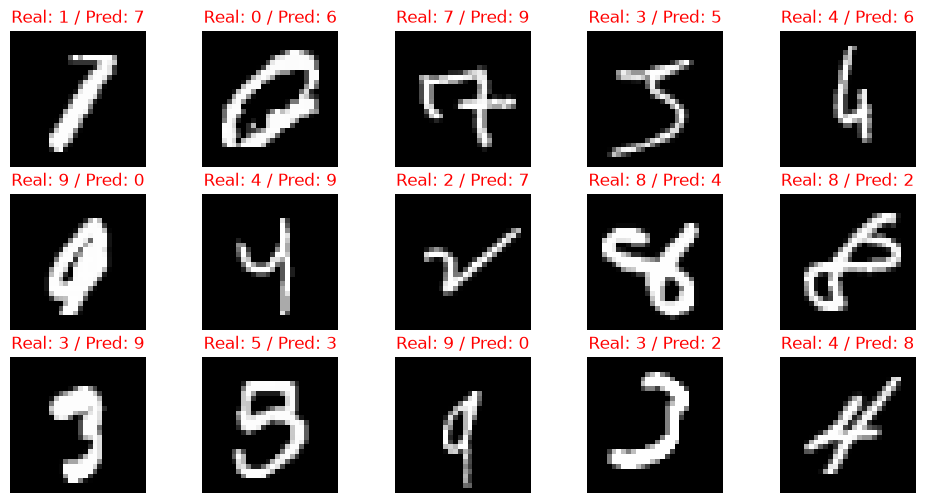

In [114]:
#errores del modelo
errores= np.where(y_pred_cnn != y_test)[0]
print('Cantidad de errores', len(errores), 'de', len(y_test))
plt.figure(figsize=(12,6))
for i, idx in enumerate(errores[:15]):
  plt.subplot(3,5,i+1)
  plt.imshow(x_test[idx].reshape(28,28), cmap='gray')
  plt.title('Real: '+str(y_test[idx])+' / Pred: '+str(y_pred_cnn[idx]), color='red')
  plt.axis('off')
plt.show()

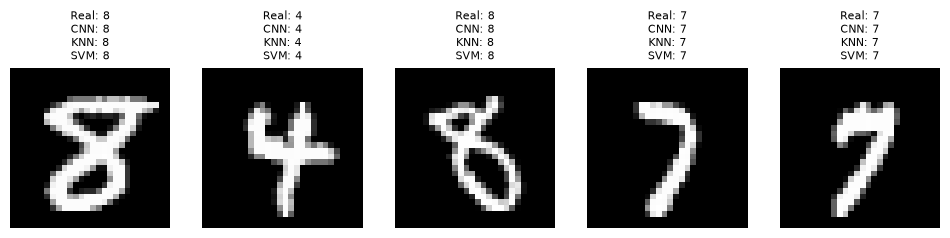

In [115]:
#comparación de un mismo grupo de dígitos en todos los modelos
plt.figure(figsize=(12,6))
for i in range(5):
  plt.subplot(1,5,i+1)
  plt.imshow(x_test[i].reshape(28,28), cmap='gray')
  txt= 'Real: '+str(y_test[i])
  for nombre, p in predicciones.items():
    txt+= '\n'+nombre+': '+str(p[i])
  plt.title(txt, fontsize=8)
  plt.axis('off')
plt.show()

## 10. Arquitectura de la red neuronal

In [116]:
arquitectura= []
for capa in model_cnn.layers:
  arquitectura.append({
      'Capa': capa.name,
      'Tipo': capa.__class__.__name__,
      'Salida': str(capa.output.shape),
      'Parámetros': capa.count_params(),
      'Activación': getattr(capa.activation, '__name__', '-') if hasattr(capa, 'activation') else '-'
  })
pd.DataFrame(arquitectura)

,Capa,Tipo,Salida,Parámetros,Activación
0,conv2d_6,Conv2D,"(None, 26, 26, 16)",160,relu
1,max_pooling2d_6,MaxPooling2D,"(None, 13, 13, 16)",0,-
2,conv2d_7,Conv2D,"(None, 11, 11, 32)",4640,relu
3,max_pooling2d_7,MaxPooling2D,"(None, 5, 5, 32)",0,-
4,conv2d_8,Conv2D,"(None, 3, 3, 64)",18496,relu
5,max_pooling2d_8,MaxPooling2D,"(None, 1, 1, 64)",0,-
6,flatten_2,Flatten,"(None, 64)",0,-
7,dense_4,Dense,"(None, 64)",4160,relu
8,dense_5,Dense,"(None, 10)",650,softmax


In [117]:
print('Optimizador:', model_cnn.optimizer.get_config()['name'])
print('Función de pérdida: sparse_categorical_crossentropy')
print('Épocas: 10 | validation_split: 0.1')
print('Total de parámetros:', model_cnn.count_params())

Optimizador: adam_2
Función de pérdida: sparse_categorical_crossentropy
Épocas: 10 | validation_split: 0.1
Total de parámetros: 28106


## 11. Ajuste de hiperparámetros y comparación final
### 11.1 Ajuste de hiperparámetros de la CNN

In [118]:
def construir_cnn(filtros=(16,32,64), densas=64, dropout=0.0, lr=0.001):
  modelo= tf.keras.models.Sequential()
  modelo.add(tf.keras.layers.Input(shape=(28,28,1)))
  for f in filtros:
    modelo.add(tf.keras.layers.Conv2D(f, 3, activation='relu'))
    modelo.add(tf.keras.layers.MaxPooling2D())
  modelo.add(tf.keras.layers.Flatten())
  modelo.add(tf.keras.layers.Dense(densas, activation='relu'))
  if dropout>0:
    modelo.add(tf.keras.layers.Dropout(dropout))
  modelo.add(tf.keras.layers.Dense(10, activation='softmax'))
  modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
  return modelo

In [119]:
#CNN: comparación de configuraciones
configuraciones= {
    'Base (16-32-64, densa 64)': dict(filtros=(16,32,64), densas=64, dropout=0.0),
    'Más filtros (32-64-128, densa 128)': dict(filtros=(32,64,128), densas=128, dropout=0.0),
    'Base + Dropout 0.4': dict(filtros=(16,32,64), densas=64, dropout=0.4),
    'Más filtros + Dropout 0.4': dict(filtros=(32,64,128), densas=128, dropout=0.4),
}
early_stop= tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

modelos_cnn= {}
historiales= {}
filas= []
for nombre, cfg in configuraciones.items():
  print('Entrenando', nombre)
  tf.keras.backend.clear_session()
  modelo= construir_cnn(**cfg)
  t0= time.time()
  h= modelo.fit(x_train_cnn, y_train, epochs=10, batch_size=64, validation_split=0.1, callbacks=[early_stop], verbose=0)
  tiempo= time.time()-t0
  mejor_ep= int(np.argmin(h.history['val_loss'])) #época de los pesos que se conservan
  modelos_cnn[nombre]= modelo
  historiales[nombre]= h.history
  filas.append({'Configuración':nombre, 'Épocas':len(h.history['loss']),
                'Accuracy entrenamiento':h.history['accuracy'][mejor_ep],
                'Accuracy validación':h.history['val_accuracy'][mejor_ep],
                'Loss validación':h.history['val_loss'][mejor_ep],
                'Tiempo (s)':tiempo})
tabla_cnn= pd.DataFrame(filas).sort_values('Accuracy validación', ascending=False).reset_index(drop=True)
tabla_cnn

Entrenando Base (16-32-64, densa 64)
Entrenando Más filtros (32-64-128, densa 128)
Entrenando Base + Dropout 0.4
Entrenando Más filtros + Dropout 0.4


,Configuración,Épocas,Accuracy entrenamiento,Accuracy validación,Loss validación,Tiempo (s)
0,Más filtros + Dropout 0.4,8,0.988016,0.988214,0.040407,43.782407
1,Base + Dropout 0.4,10,0.985992,0.987143,0.048581,30.170470
2,"Más filtros (32-64-128, densa 128)",7,0.987679,0.985179,0.047007,38.349640
3,"Base (16-32-64, densa 64)",7,0.982381,0.981429,0.058128,22.230439


Mejor configuración CNN (según validación): Más filtros + Dropout 0.4


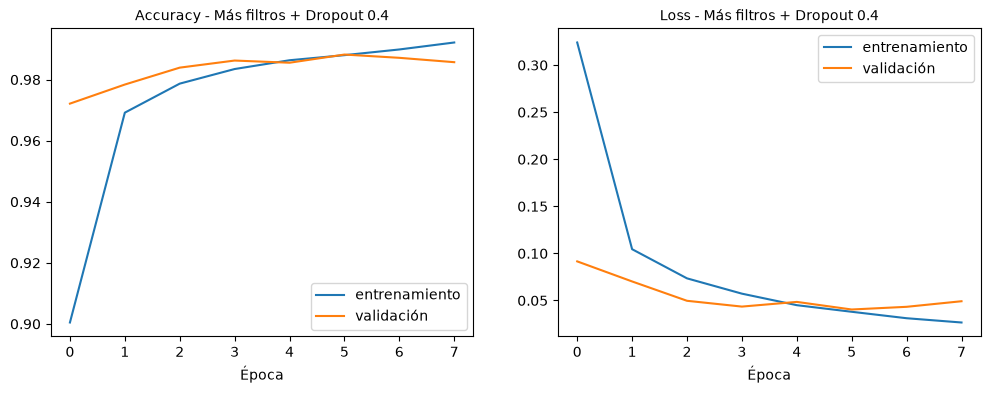

In [120]:
mejor_nombre= tabla_cnn.loc[0,'Configuración']
print('Mejor configuración CNN (según validación):', mejor_nombre)
hist= historiales[mejor_nombre]

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(hist['accuracy'], label='entrenamiento')
plt.plot(hist['val_accuracy'], label='validación')
plt.title('Accuracy - '+mejor_nombre, fontsize=10)
plt.xlabel('Época')
plt.legend()
plt.subplot(1,2,2)
plt.plot(hist['loss'], label='entrenamiento')
plt.plot(hist['val_loss'], label='validación')
plt.title('Loss - '+mejor_nombre, fontsize=10)
plt.xlabel('Época')
plt.legend()
plt.show()

438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Metricas del modelo CNN ajustada
Accuracy 0.9863571428571428
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1343
           1       0.99      0.99      0.99      1600
           2       0.99      0.97      0.98      1380
           3       0.99      0.98      0.99      1433
           4       0.98      0.99      0.99      1295
           5       0.99      0.99      0.99      1273
           6       0.99      1.00      0.99      1396
           7       0.97      0.99      0.98      1503
           8       0.98      0.97      0.98      1357
           9       0.98      0.98      0.98      1420

    accuracy                           0.99     14000
   macro avg       0.99      0.99      0.99     14000
weighted avg       0.99      0.99      0.99     14000



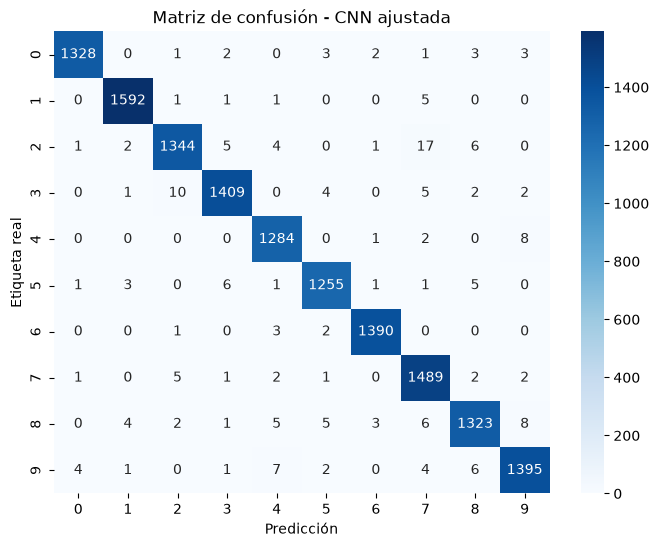

In [121]:
#EVALUACIÓN EN TEST DE LA CNN AJUSTADA
model_cnn_aj= modelos_cnn[mejor_nombre]
y_pred_cnn_aj= model_cnn_aj.predict(x_test_cnn).argmax(1)
evaluar('CNN ajustada', y_test, y_pred_cnn_aj, tabla_cnn.loc[0,'Tiempo (s)'])
matriz_confusion('CNN ajustada', y_test, y_pred_cnn_aj)

### 11.2 Comparación final e interpretación de resultados

In [122]:
tabla= pd.DataFrame(resultados).T.sort_values('Accuracy', ascending=False)
tabla

,Accuracy,Precision,Recall,F1,Tiempo (s)
CNN ajustada,0.986357,0.986379,0.986209,0.986278,43.782407
CNN,0.981500,0.982023,0.980960,0.981322,58.279683
KNN,0.970071,0.970655,0.969671,0.970028,5.625640
SVM,0.967500,0.967321,0.967214,0.967243,28.242719


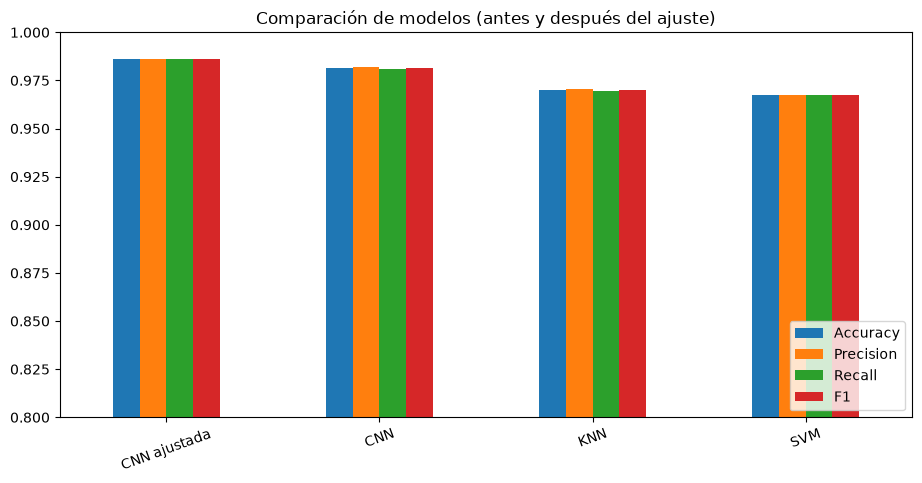

In [123]:
tabla[['Accuracy','Precision','Recall','F1']].plot(kind='bar', figsize=(11,5))
plt.title('Comparación de modelos (antes y después del ajuste)')
plt.ylim(0.8,1)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.show()

In [124]:
mejor_modelo= tabla['Accuracy'].idxmax()
print('Mejor modelo:', mejor_modelo, '| accuracy en test:', round(tabla.loc[mejor_modelo,'Accuracy'],4))
print('Mejora de la CNN con el ajuste:', round(tabla.loc['CNN ajustada','Accuracy']-tabla.loc['CNN','Accuracy'],4))

#sobreajuste: diferencia entre entrenamiento y validación de la CNN ajustada
print('Diferencia entrenamiento-validación:', round(tabla_cnn.loc[0,'Accuracy entrenamiento']-tabla_cnn.loc[0,'Accuracy validación'],4))

#dígitos más confundidos por la CNN ajustada
cm= confusion_matrix(y_test, y_pred_cnn_aj)
np.fill_diagonal(cm, 0)
pares= sorted([(cm[i,j], i, j) for i in range(10) for j in range(10) if cm[i,j]>0], reverse=True)
print('Confusiones más frecuentes:')
for n, real, pred in pares[:5]:
  print('  El', real, 'se predijo como', pred, '-', n, 'veces')

#dígitos con peor F1
f1_digitos= f1_score(y_test, y_pred_cnn_aj, average=None)
peores= np.argsort(f1_digitos)[:3]
print('Dígitos con menor F1:', [(int(d), round(float(f1_digitos[d]),4)) for d in peores])

Mejor modelo: CNN ajustada | accuracy en test: 0.9864
Mejora de la CNN con el ajuste: 0.0049
Diferencia entrenamiento-validación: -0.0002
Confusiones más frecuentes:
  El 2 se predijo como 7 - 17 veces
  El 3 se predijo como 2 - 10 veces
  El 8 se predijo como 9 - 8 veces
  El 4 se predijo como 9 - 8 veces
  El 9 se predijo como 4 - 7 veces
Dígitos con menor F1: [(8, 0.9786), (2, 0.9796), (7, 0.9819)]
